<a href="https://colab.research.google.com/github/mildrerthcamartinezl-afk/PROYECTO-BIT-MILCA/blob/main/Entregable_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Actividad 3: Taller EDA
Entrega: 21 de septiembre

Instrucciones:

Escoge un conjunto de datos de tu interés ( https://www.kaggle.com/datasets)

Utilizando Pandas, realiza:

•  Exploración de datos nulos, datos duplicados, cantidad de filas y columnas.
•  Limpieza de datos (Pandas: dropna, fillna, replace, etc.)
•  Filtrado y selección de datos relevantes para tu análisis
•  Transformación de columnas, creación de variables nuevas
•  Agrupaciones y resúmenes (groupby)

Formula al menos 5 preguntas de análisis sobre tu conjunto de datos.

Responde a las pregunta planteadas con una gráfica (con título, nombres en

los ejes, leyendas, etc) y una breve interpretación.

Conclusiones del análisis

    • Presenta al menos 3 conclusiones relevantes obtenidas a partir del análisis exploratorio.
    • Las conclusiones deben estar sustentadas en los datos y en los resultados obtenidos.
    • Menciona patrones, tendencias, relaciones o comportamientos importantes identificados en el conjunto de datos.
    • Evita limitarte a describir las gráficas; explica qué significan los resultados para el contexto del conjunto de datos."

In [1]:
"Tema elegido: Conjunto de datos financieros sintéticos de fondos de pensiones"

SyntaxError: invalid syntax (3352139405.py, line 1)

In [6]:
import pandas as pd
df = pd.read_csv("funds_augmented.csv")
df.head()

,id,Name,Year,Fin Sustainability,Inv Income,Man Fees,Fund Size,Funding Ratio
0,15,Fund 4,2018,9.214916,7.048919,0.857346,1.204630e+10,103.220679
1,7,Fund 5,2019,17.945567,8.313629,0.143566,1.000000e+00,101.740720
2,11,Fund 3,2021,25.401216,3.070155,1.892562,6.828634e+10,103.594589
3,10,Fund 8,2018,21.465490,5.637208,1.962923,1.000000e+00,100.000000
4,2,Fund 10,2022,15.326070,11.716127,-0.066588,2.739998e+09,101.864254


In [10]:
#•  Exploración de datos nulos, datos duplicados, cantidad de filas y columnas/ tenemos 3000 filas y 8 columnas o variables de análisi

df.shape

(3000, 8)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  3000 non-null   int64  
 1   Name                3000 non-null   object 
 2   Year                3000 non-null   int64  
 3   Fin Sustainability  3000 non-null   float64
 4   Inv Income          3000 non-null   float64
 5   Man Fees            3000 non-null   float64
 6   Fund Size           3000 non-null   float64
 7   Funding Ratio       3000 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 187.6+ KB


In [12]:
df.isnull().sum()

,0
id,0
Name,0
Year,0
Fin Sustainability,0
Inv Income,0
Man Fees,0
Fund Size,0
Funding Ratio,0


In [13]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#Lectura del analisis exploratorio_
#- El conjunto de datos esta compuesto por 3000 filas y 8 columnas en relación a información de fondos de pensión en tema de análisis financiero-
#- No hay valores núlos, ni duplicados en el conjunto de datos.
#- la calidad de los datos son suficientes para realizar el ejercicio de análisis y se encuentran en condiciones para proceder al segundo punto




In [14]:
df.describe()

,id,Year,Fin Sustainability,Inv Income,Man Fees,Fund Size,Funding Ratio
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3.000000e+03,3000.000000
mean,7.964000,2020.078667,15.535880,6.103925,0.921510,3.443504e+10,101.887623
std,4.294825,1.411551,7.463021,5.234509,0.637840,6.042560e+10,2.307207
min,1.000000,2018.000000,-10.527693,0.000000,-0.287726,1.000000e+00,100.000000
25%,4.000000,2019.000000,10.348664,0.815312,0.435838,1.000000e+00,100.000000
50%,8.000000,2020.000000,15.767168,5.360941,0.750214,3.826506e+09,101.222717
75%,12.000000,2021.000000,20.760542,10.141247,1.420758,3.548379e+10,103.091955
max,15.000000,2022.000000,38.948634,20.309399,2.556195,2.795601e+11,119.024938


In [15]:
df['Name'].nunique()

15

In [ ]:
#Existen 15 tipos de fondos de pension dentro del dataset, el periodo de análisi de los datos entan desde 2018 hasta el 2022, hay valores negativos en
Fin Sustainability  y Man Fees

In [16]:
#Filtrado y selección de datos relevantes para tu análisis

df_relevante = df[['Name',
                   'Year',
                   'Fin Sustainability',
                   'Inv Income',
                   'Man Fees',
                   'Fund Size',
                   'Funding Ratio']]

In [17]:
df_relevante.head()

,Name,Year,Fin Sustainability,Inv Income,Man Fees,Fund Size,Funding Ratio
0,Fund 4,2018,9.214916,7.048919,0.857346,1.204630e+10,103.220679
1,Fund 5,2019,17.945567,8.313629,0.143566,1.000000e+00,101.740720
2,Fund 3,2021,25.401216,3.070155,1.892562,6.828634e+10,103.594589
3,Fund 8,2018,21.465490,5.637208,1.962923,1.000000e+00,100.000000
4,Fund 10,2022,15.326070,11.716127,-0.066588,2.739998e+09,101.864254


In [ ]:
# El unic dato que puede ser irrelevante para el análisis corresponde al ID

In [20]:
df_relevante['Porcentaje_Comision'] = (
    df_relevante['Man Fees'] /
    df_relevante['Fund Size']
) * 100

df_relevante.head()

,Name,Year,Fin Sustainability,Inv Income,Man Fees,Fund Size,Funding Ratio,Porcentaje_Comision
0,Fund 4,2018,9.214916,7.048919,0.857346,1.204630e+10,103.220679,7.117094e-09
1,Fund 5,2019,17.945567,8.313629,0.143566,1.000000e+00,101.740720,1.435656e+01
2,Fund 3,2021,25.401216,3.070155,1.892562,6.828634e+10,103.594589,2.771509e-09
3,Fund 8,2018,21.465490,5.637208,1.962923,1.000000e+00,100.000000,1.962923e+02
4,Fund 10,2022,15.326070,11.716127,-0.066588,2.739998e+09,101.864254,-2.430203e-09


In [21]:
# Agrupaciones y resúmenes (groupby)

df_relevante.groupby('Year')['Inv Income'].mean()


,Inv Income
Year,
2018,4.440807
2019,6.028503
2020,6.687673
2021,7.186715
2022,5.958402


In [22]:
df_relevante.groupby('Year')['Fin Sustainability'].mean()

,Fin Sustainability
Year,
2018,14.836426
2019,13.944571
2020,15.535437
2021,17.645568
2022,15.205845


In [23]:
df_relevante.groupby('Year')['Funding Ratio'].mean()

,Funding Ratio
Year,
2018,102.155120
2019,101.922660
2020,101.733547
2021,101.888510
2022,101.751642


In [24]:
df_relevante.groupby('Name')['Inv Income'].mean()

,Inv Income
Name,
Fund 1,5.669997
Fund 10,6.175480
Fund 11,6.305759
Fund 12,6.372426
Fund 13,5.939098
Fund 14,6.221889
Fund 15,6.170119
Fund 2,6.496592
Fund 3,6.314953


In [ ]:
#la información por año y por fondo de pensiones. Esto permite calcular indicadores promedio de ingresos por inversión, sostenibilidad financiera y ratio de financiación, facilitando la identificación de tendencias y diferencias entre los fondos analizados.

In [ ]:
#Formula al menos 5 preguntas de análisis sobre tu conjunto de datos.
- ¿Cómo evolucionaron los ingresos promedio por inversión entre 2018 y 2022?
-¿Cómo cambió la sostenibilidad financiera promedio entre 2018 y 2022?
-¿Qué fondos presentan los mayores ingresos promedio por inversión?
- ¿Existe relación entre el tamaño del fondo  y los ingresos por inversión?
-¿Cómo se comporta el Funding Ratio a lo largo del tiempo?

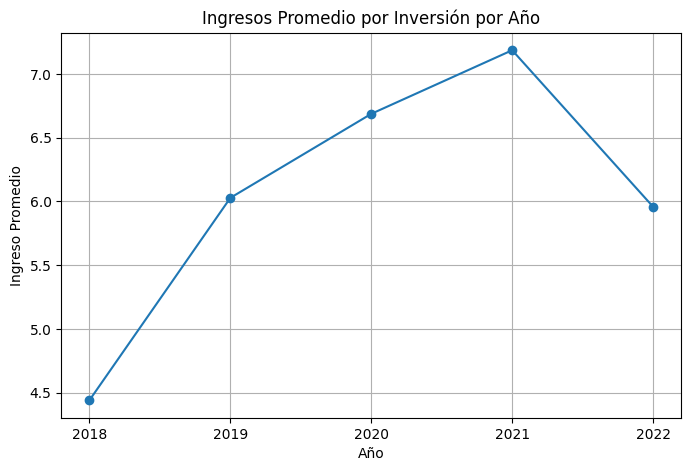

In [26]:
import matplotlib.pyplot as plt

ingresos_anio = df_relevante.groupby('Year')['Inv Income'].mean()

plt.figure(figsize=(8,5))
plt.plot(ingresos_anio.index,
         ingresos_anio.values,
         marker='o')

plt.title('Ingresos Promedio por Inversión por Año')
plt.xlabel('Año')
plt.ylabel('Ingreso Promedio')
plt.grid(True)

plt.xticks(ingresos_anio.index.astype(int))

plt.show()

In [28]:
#Los ingresos promedio por inversión mostraron una tendencia creciente entre 2018 y 2021, pasando de 4.44 a 7.19 unidades.

 #El valor más alto se registró en 2021, lo que indica un mejor desempeño de las inversiones durante ese año. Sin embargo, en 2022 se observó una disminución hasta 5.96 unidades, sugiriendo una reducción en la generación de ingresos respecto al año anterior


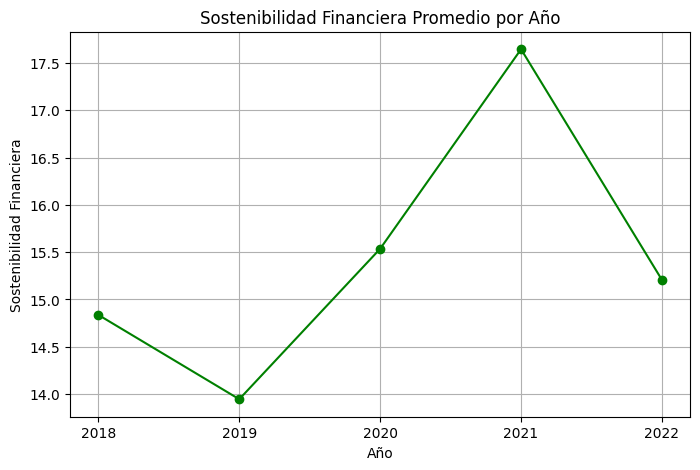

In [29]:
sostenibilidad_anio = df_relevante.groupby('Year')['Fin Sustainability'].mean()

plt.figure(figsize=(8,5))

plt.plot(
    sostenibilidad_anio.index,
    sostenibilidad_anio.values,
    marker='o',
    color='green'
)

plt.title('Sostenibilidad Financiera Promedio por Año')
plt.xlabel('Año')
plt.ylabel('Sostenibilidad Financiera')

plt.xticks(sostenibilidad_anio.index.astype(int))

plt.grid(True)

plt.show()

La sostenibilidad financiera promedio presentó variaciones durante el período analizado. En 2019 se observó una disminución respecto a 2018, seguida de una recuperación constante hasta alcanzar su valor máximo en 2021 (17.65). Posteriormente, en 2022 se registró una caída, aunque el indicador permaneció por encima de los niveles observados en 2018 y 2019. Esto sugiere que los fondos mejoraron su desempeño financiero entre 2020 y 2021, pero experimentaron una ligera reducción en su sostenibilidad durante el último año analizado.

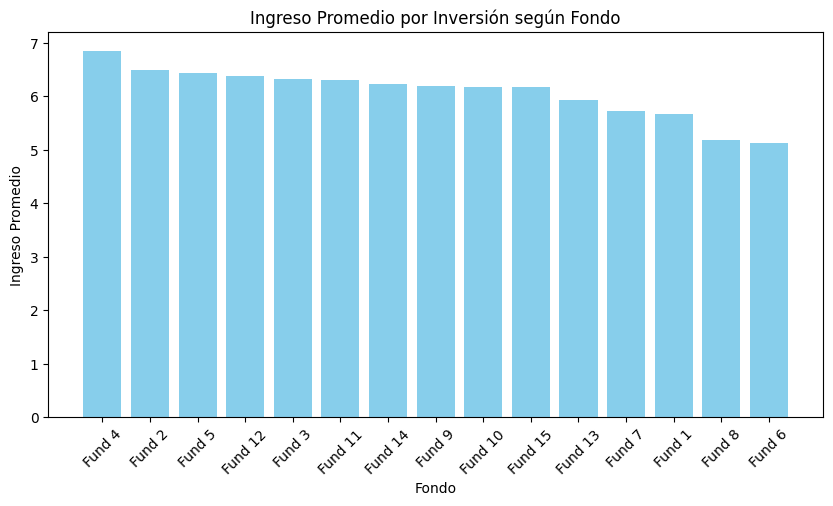

In [30]:
ingresos_fondo = (
    df_relevante.groupby('Name')['Inv Income']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))

plt.bar(
    ingresos_fondo.index,
    ingresos_fondo.values,
    color='skyblue'
)

plt.title('Ingreso Promedio por Inversión según Fondo')
plt.xlabel('Fondo')
plt.ylabel('Ingreso Promedio')

plt.xticks(rotation=45)

plt.show()

Se observan diferencias moderadas entre los fondos de pensiones en cuanto a sus ingresos promedio por inversión. El Fund 4 presenta el mayor ingreso promedio, con un valor cercano a 6.9, lo que indica un mejor desempeño en la generación de ingresos por inversiones. Por el contrario, el Fund 6 registra el valor más bajo, con aproximadamente 5.1. Aunque existen diferencias entre los fondos, todos presentan ingresos promedio relativamente cercanos, sugiriendo un comportamiento financiero relativamente homogéneo dentro del conjunto analizado.

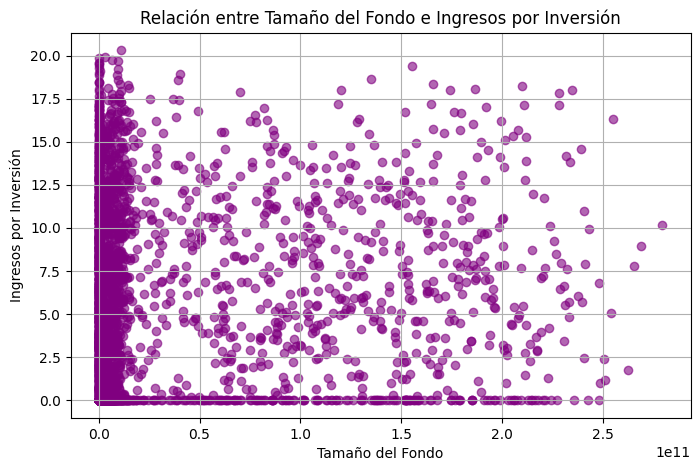

In [31]:
plt.figure(figsize=(8,5))

plt.scatter(
    df_relevante['Fund Size'],
    df_relevante['Inv Income'],
    alpha=0.6,
    color='purple'
)

plt.title('Relación entre Tamaño del Fondo e Ingresos por Inversión')
plt.xlabel('Tamaño del Fondo')
plt.ylabel('Ingresos por Inversión')

plt.grid(True)

plt.show()

Aunque intuitivamente podría pensarse que los fondos más grandes generan mayores ingresos, los datos no muestran una relación lineal fuerte entre ambas variables.

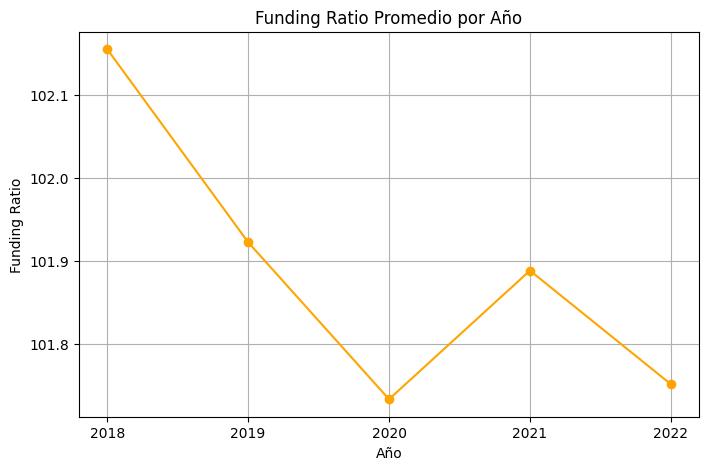

In [32]:
funding_anio = df_relevante.groupby('Year')['Funding Ratio'].mean()

plt.figure(figsize=(8,5))

plt.plot(
    funding_anio.index,
    funding_anio.values,
    marker='o',
    color='orange'
)

plt.title('Funding Ratio Promedio por Año')
plt.xlabel('Año')
plt.ylabel('Funding Ratio')

plt.xticks(funding_anio.index.astype(int))

plt.grid(True)

plt.show()

La estabilidad del indicador refleja una situación financiera sólida y un bajo nivel de riesgo en relación con el cumplimiento de los compromisos adquiridos.